<a href="https://colab.research.google.com/github/peter-adepoju/math-neuro-ml/blob/main/project/Project2_Starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MAMBA Project Week — Option 2: How Many Dimensions Does Motor Cortex Need?**

**Question.** How many dimensions of motor-cortex activity are needed to decode wheel velocity, and does the answer hold in a second mouse?

**Minimum result.** Test R² of a least-squares decoder of wheel velocity from the top k principal components (k = 1 to 50) in session 10, with PCA fitted on training trials only, and the k that reaches 90% of the best R².

**Lessons to revisit.** 5 (least squares, train/test), 7 (PCA, leakage), 15 (ridge, validation).

**Data.** `steinmetz_s10_hench_mop.npz` (and `steinmetz_s28_radnitz_mop.npz` for the stretch goal). Steinmetz et al. (2019), *Nature* 576:266–273; subsets of the Neuromatch Academy release; the original data are released under CC0.

**How to use this notebook.** Run it top to bottom: it loads the data, shows it, and works one first step for you. Cells marked `# TODO` are yours; each is followed by a check cell that prints *TODO* until your code sets the variables it names, then tests their shapes and simple sanity conditions. Add your own cells freely, but keep every array described by its shape and units.

### Set-up

In [1]:
# SETUP -- run first.
import os, urllib.request
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
PALETTE = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']   # Okabe-Ito, as in the lessons
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': False, 'figure.dpi': 100})
DATA_URL = 'https://raw.githubusercontent.com/peter-adepoju/math-neuro-ml/51d88220064023b5d3240c39e19b07acc7896f44/data/'

def load(name):
    # A local copy (here, or in the repository's data/ folder) first; otherwise download it from the pinned commit.
    for candidate in [name, os.path.join('..', 'data', name), os.path.join('..', '..', 'data', name)]:
        if os.path.exists(candidate):
            return np.load(candidate)
    urllib.request.urlretrieve(DATA_URL + name, name)
    return np.load(name)

def todo(*values):
    # True while any of the values is still None: the check cells below use it to wait for your code.
    return any(v is None for v in values)
print('Set-up complete.')

Set-up complete.


### Data tour

| Array | Shape | Meaning, units |
|---|---|---|
| `spikes` | (342, 447, 250) | (trial, neuron, 10 ms bin): spike counts |
| `wheel` | (342, 250) | wheel velocity, encoder steps per 10 ms bin |
| `R` | (342 × 50, 447) | rates in 50 ms bins (spikes/s), rows ordered trial by trial |
| `v` | (342 × 50,) | wheel velocity in the same 50 ms bins (steps/s) |

Rows from the same trial are correlated, so the split is **by trial**: 60% training, 20% validation, 20% test.

R: (17100, 447)  v: (17100,)  rows train/val/test: 10250 3400 3450


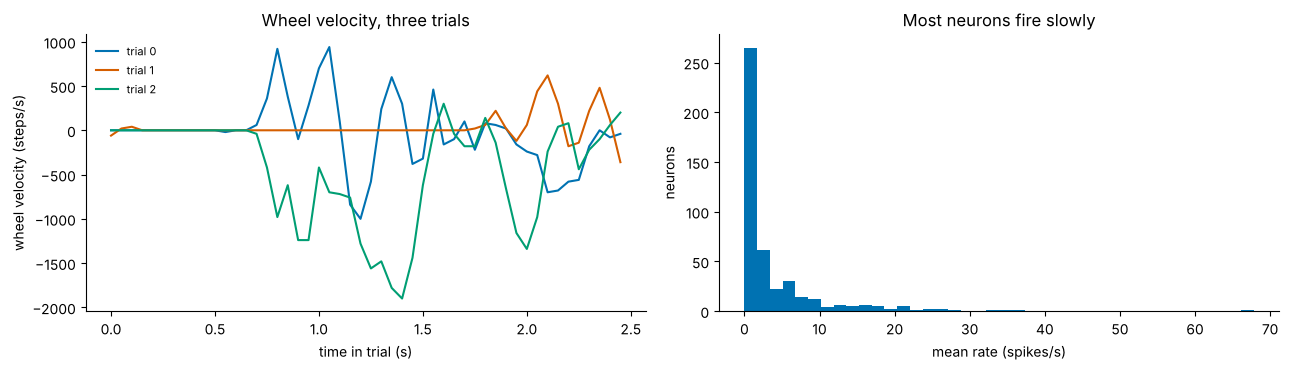

In [2]:
d = load('steinmetz_s10_hench_mop.npz')
n_tr, n_neu, n_bin = d['spikes'].shape
R = (d['spikes'].reshape(n_tr, n_neu, 50, 5).sum(axis=3) / 0.05).transpose(0, 2, 1).reshape(-1, n_neu)   # (17100, 447) spikes/s
v = (d['wheel'].reshape(n_tr, 50, 5).sum(axis=2) / 0.05).reshape(-1)                                       # (17100,) steps/s
trial_of_row = np.repeat(np.arange(n_tr), 50)
perm = rng.permutation(n_tr)
tr_tr, va_tr = perm[: int(0.6 * n_tr)], perm[int(0.6 * n_tr): int(0.8 * n_tr)]
tr, va = np.isin(trial_of_row, tr_tr), np.isin(trial_of_row, va_tr)
te = ~(tr | va)
print("R:", R.shape, " v:", v.shape, " rows train/val/test:", tr.sum(), va.sum(), te.sum())

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
t = np.arange(50) * 0.05
for k, c in zip(range(3), PALETTE):
    axes[0].plot(t, v[trial_of_row == k], color=c, label=f'trial {k}')
axes[0].set_xlabel('time in trial (s)'); axes[0].set_ylabel('wheel velocity (steps/s)'); axes[0].set_title('Wheel velocity, three trials'); axes[0].legend(fontsize=8, frameon=False)
axes[1].hist(R.mean(axis=0), bins=40, color=PALETTE[0])
axes[1].set_xlabel('mean rate (spikes/s)'); axes[1].set_ylabel('neurons'); axes[1].set_title('Most neurons fire slowly')
plt.tight_layout(); plt.show()

### Worked first step: least squares on all neurons

In [3]:
def r2(pred, target):
    return 1 - np.sum((target - pred)**2) / np.sum((target - target.mean())**2)
mu_x = R[tr].mean(axis=0)
D = np.column_stack([np.ones(len(R)), R - mu_x])                 # (17100, 448) design with intercept
beta = np.linalg.lstsq(D[tr], v[tr], rcond=None)[0]
print(f"least squares, all {n_neu} neurons: train R^2 {r2(D[tr] @ beta, v[tr]):.3f}, test R^2 {r2(D[te] @ beta, v[te]):.3f}")

least squares, all 447 neurons: train R^2 0.838, test R^2 0.808


In [4]:
# TODO 1 -- PCA decoders (Lesson 7). Standardise with TRAINING means and SDs (drop neurons with SD 0 in training), fit PCA
# on the training rows only, and for k = 1 ... 50 fit least squares of v on [1, top-k scores] (training rows) and store
# the test R^2 in r2_k (shape (50,)). Plot r2_k against k.
r2_k = None

In [5]:
if todo(r2_k):
    print('TODO 1 not done yet.')
else:
    assert np.shape(r2_k) == (50,)
    print('Check 1 passed.')

TODO 1 not done yet.


In [6]:
# TODO 2 -- Ridge on all neurons (Lesson 15). For lam in [1, 10, 100, 1000, 10000, 100000], fit ridge regression on the
# standardised rates (intercept not penalised), choose lam on the VALIDATION rows, and store the chosen lam in lam_best
# and its test R^2 in r2_ridge.
lam_best = r2_ridge = None

In [7]:
if todo(lam_best, r2_ridge):
    print('TODO 2 not done yet.')
else:
    assert -1 < r2_ridge <= 1
    print('Check 2 passed.')

TODO 2 not done yet.


In [8]:
# TODO 3 -- Store in k90 the smallest k whose PCA test R^2 reaches 90% of max(r2_k.max(), r2_ridge).
k90 = None

In [9]:
if todo(k90):
    print('TODO 3 not done yet (or no k reaches 90%: say so in your talk).')
else:
    assert 1 <= k90 <= 50
    print('Check 3 passed.')

TODO 3 not done yet (or no k reaches 90%: say so in your talk).


### Before the talk
- Fit every preprocessing step (means, SDs, PCA) on training trials only, and say so.
- The decoder uses one 50 ms bin; Lesson 5 found that the same bin decodes best, but say that lags were not explored.
- Stretch: `steinmetz_s28_radnitz_mop.npz` has 180 MOp neurons in 128 trials. The neurons differ, so compare the shape of the R² curve, not the weights.